# Aula 05 · Vídeo 3 — DPIA, Consentimento Granular e Direitos do Titular

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs · **Caso condutor:** Banco **Aurora** / **Aurora Assist**
> **Tipo:** conceitual **+** prático · **Doc 04:** seções 3 (direitos/consentimento), 8 (DPIA/Privacy by Design), 9 (explicação), 10 (esquecimento/unlearning)

## 🎯 Objetivos
- Implementar **consentimento granular e versionado** (Snippet 1) e a **revogação instantânea**.
- Mapear os **direitos do titular** (arts. 17-22) em requisitos técnicos.
- Conduzir uma **DPIA** e operacionalizar o **direito ao esquecimento** com purga seletiva no vector store.

> [!WARNING]
> ⚠️ **Uso ético.** PII 100% sintética; o objetivo é aprender a **proteger** o dado (Doc 04).

## 1. Teoria (Doc 04, §3 / Hands On) — consentimento granular e versionado

> *"Qual versão dos termos o titular aceitou, e quando?"* — pergunta do auditor da ANPD

Cada finalidade recebe um consentimento **específico**; cada escolha gera uma **versão** auditável e **revogável**. Consultar saldo apoia-se em *execução de contrato*; usar conversas para treino exige **consentimento** (art. 7).

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print('ROOT =', ROOT)

ROOT = /Users/miyake-san/Projects/9mlet-llm-security/aula05_conformidade_lgpd_gdpr


In [2]:
from src.security.consent import InMemoryConsentStore
from src.security.schemas import ConsentRecord

store = InMemoryConsentStore()
# v1: o titular consente consulta de saldo, mas NÃO o treino do modelo.
store.upsert(ConsentRecord(subject_id='cli-90432',
                           purposes={'consulta_saldo': True, 'treino_modelo': False},
                           terms_version='2026-06-v3'))
# v2: mais tarde, passa a consentir o treino.
store.upsert(ConsentRecord(subject_id='cli-90432',
                           purposes={'consulta_saldo': True, 'treino_modelo': True},
                           terms_version='2026-06-v3'))

atual = store.get('cli-90432')
print('Versão vigente:', atual.version)
print('Permite treino_modelo? ->', atual.allows('treino_modelo'))
print('\nHistórico versionado (trilha auditável):')
for r in store.history('cli-90432'):
    print(f"  v{r.version} | treino={r.purposes.get('treino_modelo')} | {r.timestamp}")

Versão vigente: 2
Permite treino_modelo? -> True

Histórico versionado (trilha auditável):
  v1 | treino=False | 2026-08-26T14:20:06Z
  v2 | treino=True | 2026-08-26T14:20:06Z


In [3]:
# Revogação instantânea (art. 18, IX): nova versão com revoked=True.
store.revoke('cli-90432')
atual = store.get('cli-90432')
print('Após revogar -> versão:', atual.version, '| revoked:', atual.revoked)
print('Permite treino_modelo agora? ->', atual.allows('treino_modelo'))

Após revogar -> versão: 3 | revoked: True
Permite treino_modelo agora? -> False


## 2. Direitos do titular (Doc 04, §3) — arts. 17 a 22

Cada direito no papel vira um **requisito de engenharia**: acesso = recuperar tudo o que sabemos; exclusão = apagar de bancos, caches e *embeddings*; revisão = permitir contestar decisão automatizada.

In [4]:
from src.security.regulations import DATA_SUBJECT_RIGHTS

print('Direito                       | LGPD        | GDPR   | Descrição')
print('-' * 82)
for right, m in DATA_SUBJECT_RIGHTS.items():
    print(f"{right.value:29s} | {m['lgpd']:11s} | {m['gdpr']:6s} | {m['desc']}")

Direito                       | LGPD        | GDPR   | Descrição
----------------------------------------------------------------------------------
confirmacao_e_acesso          | art. 18, I-II | art. 15 | Confirmação e acesso aos dados.
correcao                      | art. 18, III | art. 16 | Correção de dados incompletos.
eliminacao                    | art. 18, VI | art. 17 | Eliminação (direito ao esquecimento).
portabilidade                 | art. 18, V  | art. 20 | Portabilidade dos dados.
informacao_compartilhamento   | art. 18, VII | art. 19 | Info sobre compartilhamentos.
revogacao_consentimento       | art. 18, IX | art. 7(3) | Revogação do consentimento.
revisao_decisao_automatizada  | art. 20     | art. 22 | Revisão de decisão automatizada.


## 3. Teoria (Doc 04, §8) — DPIA e Privacy by Design

A **DPIA** (RIPD na LGPD) identifica, avalia e mitiga riscos **antes** do lançamento. É onde a engenharia das Aulas 2-4 vira **evidência jurídica**: cada risco é documentado ao lado da mitigação concreta e submetido ao DPO. O **Privacy by Design** (Cavoukian, 2009; GDPR art. 25) incorpora privacidade desde a concepção.

In [5]:
from src.security.dpia import run_dpia, dpia_to_markdown

dpia = run_dpia()
print('Sistema:', dpia.system_name)
print('Nível EU AI Act:', dpia.risk_tier.value)
print('Risco agregado R =', dpia.aggregate_risk, '-> decisão:', dpia.decision)
print('\nCenários e mitigações:')
for s in dpia.scenarios:
    print(f'  - {s.name:32s} P={s.probability:.2f} | mitig.: {s.mitigation}')

Sistema: Aurora Assist
Nível EU AI Act: limited
Risco agregado R = 0.1032 -> decisão: accept

Cenários e mitigações:
  - vazamento_de_pii                 P=0.10 | mitig.: Guardrail de saída (Aula 2) + minimização com Presidio (Aula 3).
  - tratamento_sem_base_legal        P=0.05 | mitig.: Consentimento granular versionado + enforcement na rag-api.
  - decisao_automatizada_de_credito  P=0.08 | mitig.: Recusa de decisão automatizada (GDPR art. 22) + human-in-the-loop.
  - retencao_excessiva               P=0.20 | mitig.: Política de retenção por finalidade + purga programada.
  - transferencia_internacional      P=0.15 | mitig.: Residência em Azure Brazil South + Customer-Managed Keys (Aula 3).


In [6]:
from IPython.display import Markdown

# A DPIA renderizada é a evidência entregue ao DPO (art. 35).
Markdown(dpia_to_markdown(dpia))

# DPIA / RIPD — Aurora Assist

> Data Protection Impact Assessment (GDPR art. 35 / LGPD art. 38).
> Gerado por `app/dpia.py` a partir de `configs/` — Doc 04, §7-8.

## 1. Classificação de risco (EU AI Act)
- **Nível:** `limited`
- **Decisão sobre o risco agregado:** `accept`
- **Risco agregado R = Σ Pj·Ij (normalizado):** `0.1032`

### Obrigações herdadas
- transparencia_ao_usuario
- documentacao_minima

## 2. Cenários de risco e mitigações
| Cenário | P | Impacto | Mitigação |
|---|---|---|---|
| vazamento_de_pii | 0.10 | pii_leak | Guardrail de saída (Aula 2) + minimização com Presidio (Aula 3). |
| tratamento_sem_base_legal | 0.05 | unlawful_basis | Consentimento granular versionado + enforcement na rag-api. |
| decisao_automatizada_de_credito | 0.08 | automated_decision | Recusa de decisão automatizada (GDPR art. 22) + human-in-the-loop. |
| retencao_excessiva | 0.20 | retention_excess | Política de retenção por finalidade + purga programada. |
| transferencia_internacional | 0.15 | cross_border | Residência em Azure Brazil South + Customer-Managed Keys (Aula 3). |

## 3. Riscos residuais e limites técnicos (honestidade intelectual)
- Direito à explicação: LLM é caixa-preta; explicação ex-post é limite técnico em aberto (Doc 04, §9 — Wachter et al., 2017).
- Machine unlearning: purga de vetores cobre o RAG, mas não o conhecimento de fine-tuning (Doc 04, §10 — Bourtoule et al., 2021). Decisão arquitetural: evitar treinar com dados pessoais.
- Classificação EU AI Act: limited — Art. 50: interação direta com pessoas exige transparência.

## 4. Privacy by Design (GDPR art. 25)
- Minimização e anonimização desde a concepção (Aula 3 — Presidio).
- Privacidade como configuração padrão (proativo, não reativo).
- Residência de dados e Customer-Managed Keys (soberania — Schrems II).


## 4. Teoria (Doc 04, §9-10) — explicação e esquecimento

O **direito à explicação** esbarra na natureza de **caixa-preta** do LLM (Wachter et al., 2017). O **direito ao esquecimento** tem duas camadas: na **recuperação** (RAG), a purga seletiva de vetores resolve; no **modelo**, o conhecimento de *fine-tuning* exige **machine unlearning** — área imatura. Formalmente, busca-se $\theta_{\text{unlearn}}$ indistinguível de um retreino sem o dado $x$:

$$
\mathcal{D}\big(\theta_{\text{unlearn}}(D \setminus \{x\}) \,\Vert\, \theta_{\text{retrain}}(D \setminus \{x\})\big) \le \epsilon
$$

In [7]:
from src.security.vector_store import InMemoryVectorStore, VectorRecord

vs = InMemoryVectorStore()
# Documentos institucionais + de dois titulares (alguns com PII).
vs.upsert(VectorRecord('inst-1', 'banco', 'Horários e tarifas das agências Aurora.'))
vs.upsert(VectorRecord('a-1', 'cli-90432', 'Atendimento: cliente pediu 2a via (CPF sintético).'))
vs.upsert(VectorRecord('a-2', 'cli-90432', 'Atendimento: atualização de cadastro.'))
vs.upsert(VectorRecord('b-1', 'cli-90777', 'Atendimento de outro titular.'))
print('Total de vetores:', vs.count())
print('Do titular cli-90432:', [r.doc_id for r in vs.list_by_subject('cli-90432')])

Total de vetores: 4
Do titular cli-90432: ['a-1', 'a-2']


Purga seletiva: 2 vetor(es) do titular removidos.
Documentos remanescentes: ['b-1', 'inst-1']


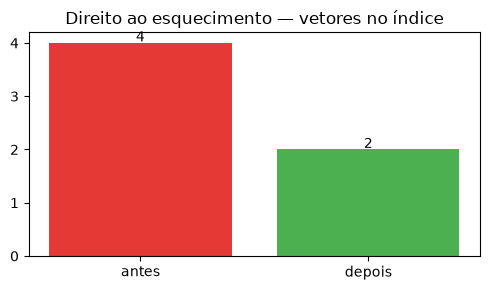

In [8]:
import matplotlib.pyplot as plt

before = vs.count()
result = vs.purge_subject('cli-90432')     # direito ao esquecimento (Snippet 3)
after = vs.count()
print(f'Purga seletiva: {result.deleted_count} vetor(es) do titular removidos.')
print('Documentos remanescentes:',
      [rec.doc_id for rec, _score in vs.search('atendimento', top_k=5)])

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['antes', 'depois'], [before, after], color=['#e53935', '#4caf50'])
ax.set_title('Direito ao esquecimento — vetores no índice')
for i, v in enumerate([before, after]):
    ax.text(i, v + 0.03, str(v), ha='center')
plt.tight_layout(); plt.show()

In [9]:
# Honestidade técnica: a purga cobre o RAG, não o fine-tuning (Doc 04, §10).
print(result.model_unlearning_note)

Purga na camada de RECUPERAÇÃO concluída. O conhecimento absorvido em fine-tuning NÃO é endereçável por delete (Doc 04, §10 — machine unlearning aproximado). Limite registrado no DPIA.


## ✅ Resumo e gancho

- **Consentimento granular e versionado** responde ao auditor e permite revogação instantânea.
- **DPIA** converte defesas técnicas em evidência jurídica para o DPO.
- **Direito ao esquecimento**: purga seletiva no RAG; *unlearning* aproximado no modelo é limite honesto na DPIA.

➡️ **Vídeo 4 (Lab):** um **pipeline LGPD-compliant** ponta a ponta — consentimento, minimização, registro de tratamento (WORM) e purga — consumindo a stack em Docker.